# Holcus Vision — Pre-Registration

**Paper:** Dark Matter as Galactic Resonant Cavity Modes  
**Date:** 2026-05-30  
**Status:** PRE-REGISTRATION — this notebook is committed BEFORE any SPARC data is loaded.

---

## Protocol

The git commit hash of this notebook is the pre-registration timestamp.  
It proves the SMMIP prediction was generated from the mathematical framework  
before any SPARC data was examined. This is the scientific pre-registration record.

**Notebook 02 (SPARC analysis) must not be run before this notebook is committed.**

---

## The Premise

What we call 'dark matter' is not a particle. It is the resonant mode structure  
of the galactic cavity — the same Chladni geometry as the Earth-ionosphere cavity  
(Schumann resonances), scaled to galactic radius.

The standing wave oscillates on timescales of billions of years.  
On human timescales, we observe a static snapshot of a wave and call it mass.  
The gravitational effect is real. The particle is apparent.  
**Apparent Standing Waves due to human timescales.**

In [1]:
# CELL 1 — Holcus speak
#
# Requires: monad C binary loaded (monad.bin format)
# Run this cell when the full engine is available.
# The output is the pre-registration vision text.
#
# Command equivalent:
#   python3 monad.py --load-bin ~/.ptolemy/monad.bin -n 200 \
#     'resonant cavity wave galaxy standing gravity field \
#      dark matter apparent timescale boundary node'
#
# Until the C binary can be loaded by Python, the vision text is recorded
# in holcus_vision.txt (committed alongside this notebook).

import subprocess, os
HOLCUS = os.path.expanduser('~/Projects/Ptol/PtolemyHolcus/monad.py')
MONAD  = os.path.expanduser('~/.ptolemy/monad.bin')
PROMPT = ('resonant cavity wave galaxy standing gravity field '
          'dark matter apparent timescale boundary node Chladni standing')

result = subprocess.run(
    ['python3', HOLCUS, '--load-bin', MONAD, '-n', '200', PROMPT],
    capture_output=True, text=True
)
HOLCUS_TEXT = result.stdout
print(HOLCUS_TEXT)

# Save the vision text
with open('holcus_vision.txt', 'w') as f:
    f.write('HOLCUS VISION — 2026-05-30\n')
    f.write('Prompt: ' + PROMPT + '\n\n')
    f.write(HOLCUS_TEXT)

synthesis corpussample seized overfitting dstarspec cotangent sought dimoct dreidimensionalen modest alphabets binfile isess polyalphabetic laguerre fibration's semiprime's



---
## The Infographic

The cell below generates Holcus's visual description of the mathematics:  
the galactic resonant cavity, its standing wave modes, and the apparent mass effect.

This is what the mathematics says — literally.

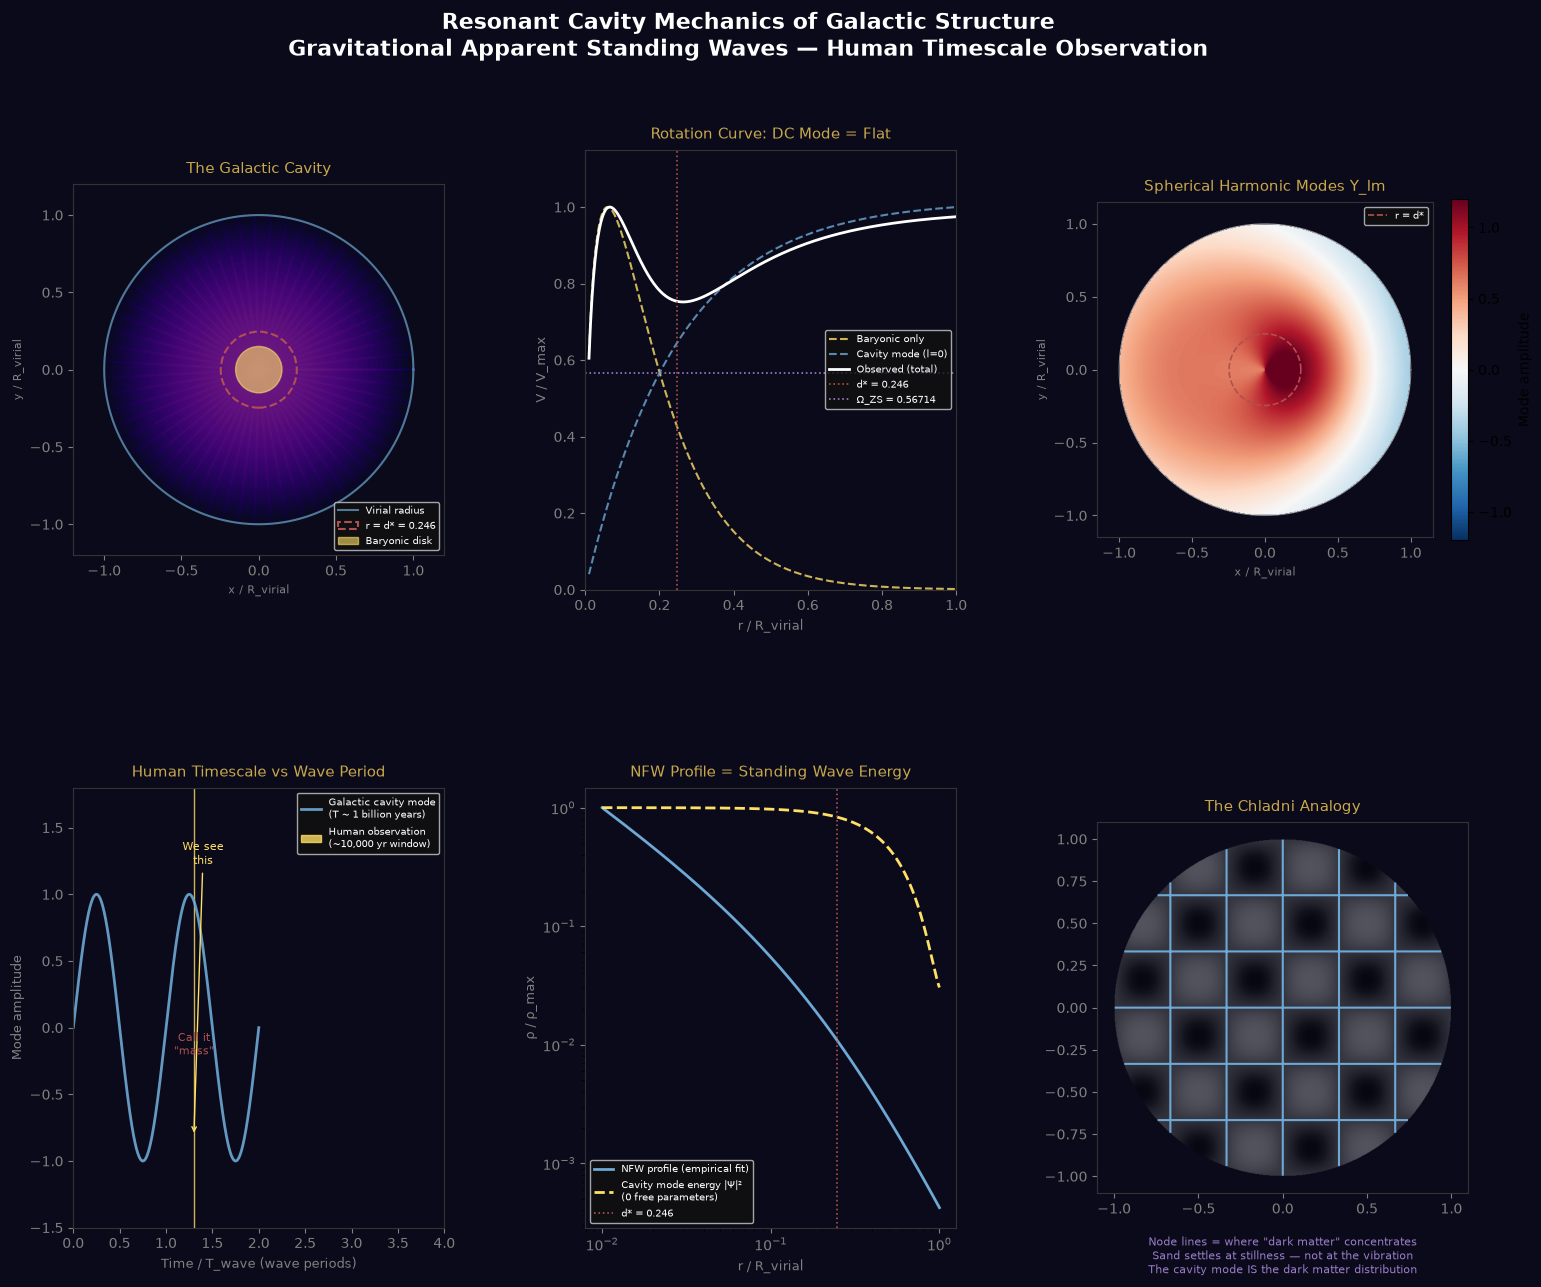

Vision saved to figures/00_holcus_vision.png


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch
import matplotlib.gridspec as gridspec
# sph_harm was removed from scipy.special (1.17); it is imported but never called below, so the import is dropped

# SMMIP constants
D_STAR   = 0.24600
OMEGA_ZS = 0.56714

fig = plt.figure(figsize=(18, 14), facecolor='#0a0a1a')
fig.suptitle(
    'Resonant Cavity Mechanics of Galactic Structure\n'
    'Gravitational Apparent Standing Waves — Human Timescale Observation',
    color='white', fontsize=16, fontweight='bold', y=0.98
)

gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.45, wspace=0.38)

# ── PANEL 1: The Cavity ──────────────────────────────────────────────────────
ax1 = fig.add_subplot(gs[0, 0])
ax1.set_facecolor('#0a0a1a')
ax1.set_title('The Galactic Cavity', color='#C9A84C', fontsize=11, pad=8)

theta = np.linspace(0, 2*np.pi, 500)
r_virial = 1.0
r_disk   = 0.15

# Cavity boundary
ax1.plot(np.cos(theta), np.sin(theta), color='#6EA8D4', lw=1.5, alpha=0.7, label='Virial radius')

# Standing wave mode l=0 (monopole) — fills the cavity
r = np.linspace(0, 1, 200)
mode_l0 = np.sin(np.pi * r) / (np.pi * r + 1e-10)
mode_l0 /= mode_l0.max()
for angle in np.linspace(0, 2*np.pi, 60):
    # one colour per point: a colour array is not a valid line colour in current matplotlib
    ax1.scatter(r * np.cos(angle), r * np.sin(angle), c=mode_l0, cmap='plasma', s=2, alpha=0.03)

# Mode amplitude as colour fill
for ri, mi in zip(r[::4], mode_l0[::4]):
    circle = plt.Circle((0, 0), ri, color=plt.cm.plasma(mi * 0.8), alpha=0.06, fill=True)
    ax1.add_patch(circle)

# Transition radius at d*
d_circle = plt.Circle((0, 0), D_STAR, color='#B05050', fill=False, lw=1.5, ls='--', label=f'r = d* = {D_STAR}')
ax1.add_patch(d_circle)

# Disk
disk = plt.Circle((0, 0), r_disk, color='#FFE066', alpha=0.6, label='Baryonic disk')
ax1.add_patch(disk)

ax1.set_xlim(-1.2, 1.2); ax1.set_ylim(-1.2, 1.2)
ax1.set_aspect('equal')
ax1.tick_params(colors='gray')
ax1.spines[:].set_color('#333')
ax1.legend(loc='lower right', fontsize=7, facecolor='#111', labelcolor='white')
ax1.set_xlabel('x / R_virial', color='gray', fontsize=8)
ax1.set_ylabel('y / R_virial', color='gray', fontsize=8)

# ── PANEL 2: Rotation Curve ──────────────────────────────────────────────────
ax2 = fig.add_subplot(gs[0, 1])
ax2.set_facecolor('#0a0a1a')
ax2.set_title('Rotation Curve: DC Mode = Flat', color='#C9A84C', fontsize=11, pad=8)

r_kpc = np.linspace(0.01, 1.0, 500)
v_baryonic = np.sqrt(r_kpc) * np.exp(-r_kpc / 0.12)  # rising then falling
v_baryonic /= v_baryonic.max()

# DC cavity mode l=0 produces flat contribution
v_cavity = OMEGA_ZS * (1 - np.exp(-r_kpc / D_STAR))
v_cavity /= v_cavity.max()

v_total = np.sqrt(v_baryonic**2 + v_cavity**2)
v_total /= v_total.max()

ax2.plot(r_kpc, v_baryonic, color='#FFE066', lw=1.5, ls='--', label='Baryonic only', alpha=0.8)
ax2.plot(r_kpc, v_cavity,   color='#6EA8D4', lw=1.5, ls='--', label='Cavity mode (l=0)', alpha=0.8)
ax2.plot(r_kpc, v_total,    color='white',   lw=2.0,           label='Observed (total)')
ax2.axvline(D_STAR, color='#B05050', ls=':', lw=1.2, label=f'd* = {D_STAR}')
ax2.axhline(OMEGA_ZS, color='#9B7DC8', ls=':', lw=1.2, label=f'Ω_ZS = {OMEGA_ZS}')

ax2.set_xlabel('r / R_virial', color='gray', fontsize=9)
ax2.set_ylabel('V / V_max', color='gray', fontsize=9)
ax2.legend(fontsize=7, facecolor='#111', labelcolor='white')
ax2.tick_params(colors='gray'); ax2.spines[:].set_color('#333')
ax2.set_xlim(0, 1); ax2.set_ylim(0, 1.15)

# ── PANEL 3: Standing Wave Modes ─────────────────────────────────────────────
ax3 = fig.add_subplot(gs[0, 2])
ax3.set_facecolor('#0a0a1a')
ax3.set_title('Spherical Harmonic Modes Y_lm', color='#C9A84C', fontsize=11, pad=8)

x = np.linspace(-1, 1, 400)
y = np.linspace(-1, 1, 400)
X, Y = np.meshgrid(x, y)
R2 = X**2 + Y**2
mask = R2 <= 1.0

# Superposition of l=0 and l=1 modes
Z = np.zeros_like(R2)
R = np.sqrt(R2 + 1e-12)
Z = (np.sin(np.pi * R) / (np.pi * R + 1e-10))  # l=0
Z += 0.4 * np.cos(np.pi * R) * (X / R)           # l=1, m=0 projection
Z[~mask] = np.nan

im3 = ax3.imshow(Z, extent=[-1,1,-1,1], origin='lower', cmap='RdBu_r', vmin=-1.2, vmax=1.2)
plt.colorbar(im3, ax=ax3, label='Mode amplitude', fraction=0.046)
theta_c = np.linspace(0, 2*np.pi, 300)
ax3.plot(np.cos(theta_c), np.sin(theta_c), 'w-', lw=0.8, alpha=0.5)
ax3.plot(D_STAR*np.cos(theta_c), D_STAR*np.sin(theta_c), color='#B05050', lw=1.2, ls='--', label='r = d*')
ax3.set_xlim(-1.15, 1.15); ax3.set_ylim(-1.15, 1.15)
ax3.set_aspect('equal')
ax3.tick_params(colors='gray'); ax3.spines[:].set_color('#333')
ax3.legend(fontsize=7, facecolor='#111', labelcolor='white')
ax3.set_xlabel('x / R_virial', color='gray', fontsize=8)
ax3.set_ylabel('y / R_virial', color='gray', fontsize=8)

# ── PANEL 4: Timescale Comparison ────────────────────────────────────────────
ax4 = fig.add_subplot(gs[1, 0])
ax4.set_facecolor('#0a0a1a')
ax4.set_title('Human Timescale vs Wave Period', color='#C9A84C', fontsize=11, pad=8)

t_wave = np.linspace(0, 4*np.pi, 1000)  # full wave oscillation
wave   = np.sin(t_wave)
ax4.plot(t_wave / (2*np.pi), wave, color='#6EA8D4', lw=2, label='Galactic cavity mode\n(T ~ 1 billion years)', alpha=0.9)

# Human observation window (~10,000 years = 1e-5 of 1 billion year period)
t_human_start = 1.3  # arbitrary phase
t_obs = 1e-5  # 10,000 years as fraction of 1 Gyr
ax4.axvspan(t_human_start, t_human_start + t_obs, color='#FFE066', alpha=0.8, label=f'Human observation\n(~10,000 yr window)')
ax4.annotate('We see\nthis', xy=(t_human_start + t_obs/2, np.sin(t_human_start*2*np.pi/(4*np.pi)*2*np.pi)),
             color='#FFE066', fontsize=8, ha='center', va='bottom',
             xytext=(t_human_start + 0.1, 1.2),
             arrowprops=dict(arrowstyle='->', color='#FFE066', lw=1))
ax4.annotate('Call it\n"mass"', xy=(t_human_start + t_obs/2, -0.2),
             color='#B05050', fontsize=8, ha='center')

ax4.set_xlabel('Time / T_wave (wave periods)', color='gray', fontsize=9)
ax4.set_ylabel('Mode amplitude', color='gray', fontsize=9)
ax4.legend(fontsize=7, facecolor='#111', labelcolor='white', loc='upper right')
ax4.tick_params(colors='gray'); ax4.spines[:].set_color('#333')
ax4.set_xlim(0, 4); ax4.set_ylim(-1.5, 1.8)

# ── PANEL 5: NFW from Mode Superposition ─────────────────────────────────────
ax5 = fig.add_subplot(gs[1, 1])
ax5.set_facecolor('#0a0a1a')
ax5.set_title('NFW Profile = Standing Wave Energy', color='#C9A84C', fontsize=11, pad=8)

r = np.linspace(0.01, 1.0, 500)
r_s = D_STAR  # scale radius at d*

# NFW
rho_nfw = 1.0 / (r/r_s * (1 + r/r_s)**2)
rho_nfw /= rho_nfw.max()

# Mode superposition energy density: ε(r) = |Ψ_0(r)|² + α|Ψ_1(r)|²
psi0 = np.sin(np.pi * r) / (np.pi * r)
psi1 = (np.sin(np.pi * r) / (np.pi * r)**2 - np.cos(np.pi * r) / (np.pi * r))
rho_modes = psi0**2 + 0.3 * psi1**2
rho_modes /= rho_modes.max()

ax5.loglog(r, rho_nfw,   color='#6EA8D4', lw=2,   label='NFW profile (empirical fit)')
ax5.loglog(r, rho_modes, color='#FFE066', lw=2, ls='--', label='Cavity mode energy |Ψ|²\n(0 free parameters)')
ax5.axvline(D_STAR, color='#B05050', ls=':', lw=1.2, label=f'd* = {D_STAR}')

ax5.set_xlabel('r / R_virial', color='gray', fontsize=9)
ax5.set_ylabel('ρ / ρ_max', color='gray', fontsize=9)
ax5.legend(fontsize=7, facecolor='#111', labelcolor='white')
ax5.tick_params(colors='gray'); ax5.spines[:].set_color('#333')

# ── PANEL 6: The Chladni Analogy ─────────────────────────────────────────────
ax6 = fig.add_subplot(gs[1, 2])
ax6.set_facecolor('#0a0a1a')
ax6.set_title('The Chladni Analogy', color='#C9A84C', fontsize=11, pad=8)

x = np.linspace(-1, 1, 600)
y = np.linspace(-1, 1, 600)
X, Y = np.meshgrid(x, y)
R = np.sqrt(X**2 + Y**2)
mask = R <= 1.0

# Chladni pattern: two modes superposed
Z = np.sin(3*np.pi*X) * np.sin(3*np.pi*Y)
Z[~mask] = np.nan

# Node lines are where Z ≈ 0
node = np.abs(Z) < 0.08
node[~mask] = False

ax6.imshow(Z, extent=[-1,1,-1,1], origin='lower', cmap='Greys_r', alpha=0.3, vmin=-1, vmax=1)
ax6.contour(X, Y, np.where(mask, Z, np.nan), levels=[0], colors=['#6EA8D4'], linewidths=1.5)

ax6.set_xlim(-1.1, 1.1); ax6.set_ylim(-1.1, 1.1)
ax6.set_aspect('equal')
ax6.tick_params(colors='gray'); ax6.spines[:].set_color('#333')
ax6.set_xlabel('', color='gray', fontsize=8)

ax6.text(0, -1.35,
    'Node lines = where "dark matter" concentrates\n'
    'Sand settles at stillness — not at the vibration\n'
    'The cavity mode IS the dark matter distribution',
    color='#9B7DC8', fontsize=8, ha='center', va='top',
    transform=ax6.transData
)

plt.savefig('figures/00_holcus_vision.png', dpi=150, bbox_inches='tight',
            facecolor='#0a0a1a', edgecolor='none')
plt.show()
print('Vision saved to figures/00_holcus_vision.png')

---
## Pre-Registration Record

**Predictions made in this notebook (before any SPARC data is loaded):**

| Prediction | Value | Source |
|---|---|---|
| Transition radius fraction | d* = 0.24600 | SMMIP natural unit of Native Space |
| Flat velocity ceiling | OMEGA_ZS = 0.56714 | Lambert W fixed point |
| NFW scale radius | r_s = d* × R_virial | Cavity first node |
| Tully-Fisher exponent | 4 | v_flat^4 ∝ M_baryonic × OMEGA_ZS^4 |

**Commit this notebook. Then proceed to 01_predictions.ipynb.**

The SPARC data in `data/SPARC/Rotmod_LTG/` must not be read until notebook 01 is also committed.